# Result analysis

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib 
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import load_case, compute_errors, print_err_mean_std, err_kde_plot, time_kde_plot, err_pointwise_plot, print_exec_times, plot_velocity
from matplotlib.colors import LogNorm
from numeric_method.numeric_method import solve_navier_stokes

import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colors import ListedColormap
import seaborn as sns
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

miktex_bin = r"C:\Users\gkova\AppData\Local\Programs\MiKTeX\miktex\bin\x64"

if miktex_bin not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + miktex_bin

In [2]:
# Specify a results directory
RESULT_DIR = "./results/2026-03-26_18_12"

# Load results
results = load_case(RESULT_DIR)

## Global Errors

#### L1 norm

In [3]:
errors = compute_errors(results, norm="1")
print_err_mean_std(errors)

numeric divergence error = 0.03951243289828715 +- 0.25429684497715305
numeric momentum error = 0.010274618800670939 +- 0.010372443361021227

u poisson error = 0.04600924422826479 +- 0.026340279173171634
p poisson error = 0.24601970387306932 +- 0.199691970439952
poisson divergence error = 0.08138229493159867 +- 0.27259858377800783
poisson momentum error = 0.011434338889731483 +- 0.013424090011041221

u navier-stokes error = 0.2194669276152246 +- 0.04403141951510649
p navier-stokes error = 0.6795923827868929 +- 0.08241262903426325
navier-stokes divergence error = 0.1547384018080805 +- 0.2715833098434162
navier-stokes momentum error = 0.08631221822631029 +- 0.13617585193197168


#### L2 Norm

In [4]:
errors = compute_errors(results, norm="2")
print_err_mean_std(errors)

numeric divergence error = 0.06622811771887585
numeric momentum error = 0.000213155372776694

u poisson error = 0.05515376366410757 +- 0.031667329339183536
p poisson error = 0.18335354358940298 +- 0.12997169346064422
poisson divergence error = 0.08093306580610926
poisson momentum error = 0.0003109502984697626

u navier-stokes error = 0.2257646359722805 +- 0.04674799992036183
p navier-stokes error = 0.6660310947360842 +- 0.07886217172722325
navier-stokes divergence error = 0.09770146717962395
navier-stokes momentum error = 0.025993661664544483


#### L infinity norm

In [7]:
errors = compute_errors(results, norm="inf")
print_err_mean_std(errors)

numeric divergence error = 0.03951243289828715
numeric momentum error = 0.010274618800670939

u poisson error = 0.07787394628864769 +- 0.03946736711610054
p poisson error = 0.14545943881916604 +- 0.08363183733393685
poisson divergence error = 0.08138229493159867
poisson momentum error = 0.011434338889731483

u navier-stokes error = 0.417662067217695 +- 0.20360172737208337
p navier-stokes error = 0.8597151910667545 +- 0.15204249484527207
navier-stokes divergence error = 0.1547384018080805
navier-stokes momentum error = 0.08631221822631029


## Per-case errors

### Comparison plot

C:\Users\gkova\AppData\Local\Temp\ipykernel_29676\2079171768.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


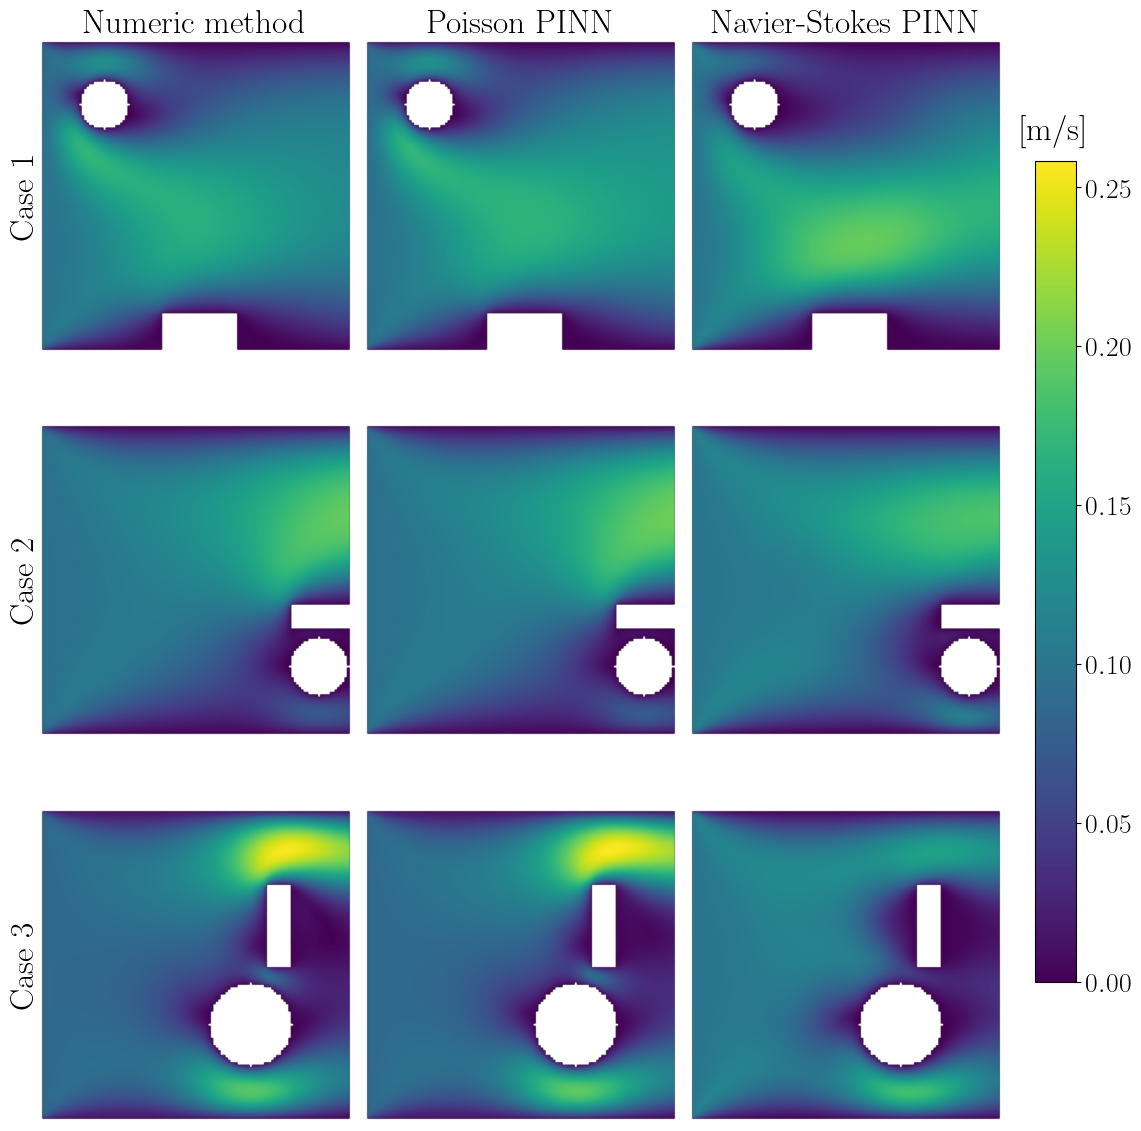

In [7]:
n_cases = 3

cmap = "viridis"

vmin = []
vmax = []

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    mag_n = np.sqrt(Un ** 2 + Vn ** 2)
    mag_p = np.sqrt(Up ** 2 + Vp ** 2)
    mag_f = np.sqrt(Uf ** 2 + Vf ** 2)

    # vmin.append(np.min([Un.min(), Vn.min(), Up.min(), Vp.min(), Uf.min(), Vf.min()]))
    # vmax.append(np.max([Un.max(), Vn.max(), Up.max(), Vp.max(), Uf.max(), Vf.max()]))

    vmin.append(np.min([mag_n.min(), mag_p.min(), mag_f.min()]))
    vmax.append(np.max([mag_n.max(), mag_p.max(), mag_f.max()]))

vmin = np.min(vmin)
vmax = np.max(vmax)

fig, ax = plt.subplots(figsize=(12, 12), nrows=n_cases, ncols=3)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    boundary = np.array(results["boundaries"][i], dtype=float)

    height, width = np.shape(results["u_numeric"][i])[0], np.shape(results["u_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, np.linspace(0, height, height) + 0.5)

    ax[i, 0].imshow(np.sqrt(Un ** 2 + Vn ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    ax[i, 1].imshow(np.sqrt(Up ** 2 + Vp ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    im = ax[i, 2].imshow(np.sqrt(Uf ** 2 + Vf ** 2), vmin=vmin, vmax=vmax, cmap=cmap)

    for j in range(3):
        ax[i, j].imshow(boundary, cmap=bw_map)

    ax[i, 0].annotate(f"Case {i+1}", xy=(-0, 0.5), xycoords="axes fraction", rotation=90, va="center", ha="right", fontsize=24)

    for j in range(3):
        ax[i, j].axis("off")

cbar = fig.colorbar(im, ax=ax[:, 2])
cbar.ax.tick_params(labelsize=20)
cbar.ax.set_title(r"[m/s]", fontsize=24, pad=15)

ax[0, 0].set_title("Numeric method", fontsize=24)
ax[0, 1].set_title("Poisson PINN", fontsize=24)
ax[0, 2].set_title("Navier-Stokes PINN", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig("flow_examples.pdf")

### Comparison plot (pressure)

C:\Users\gkova\AppData\Local\Temp\ipykernel_28860\336659275.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


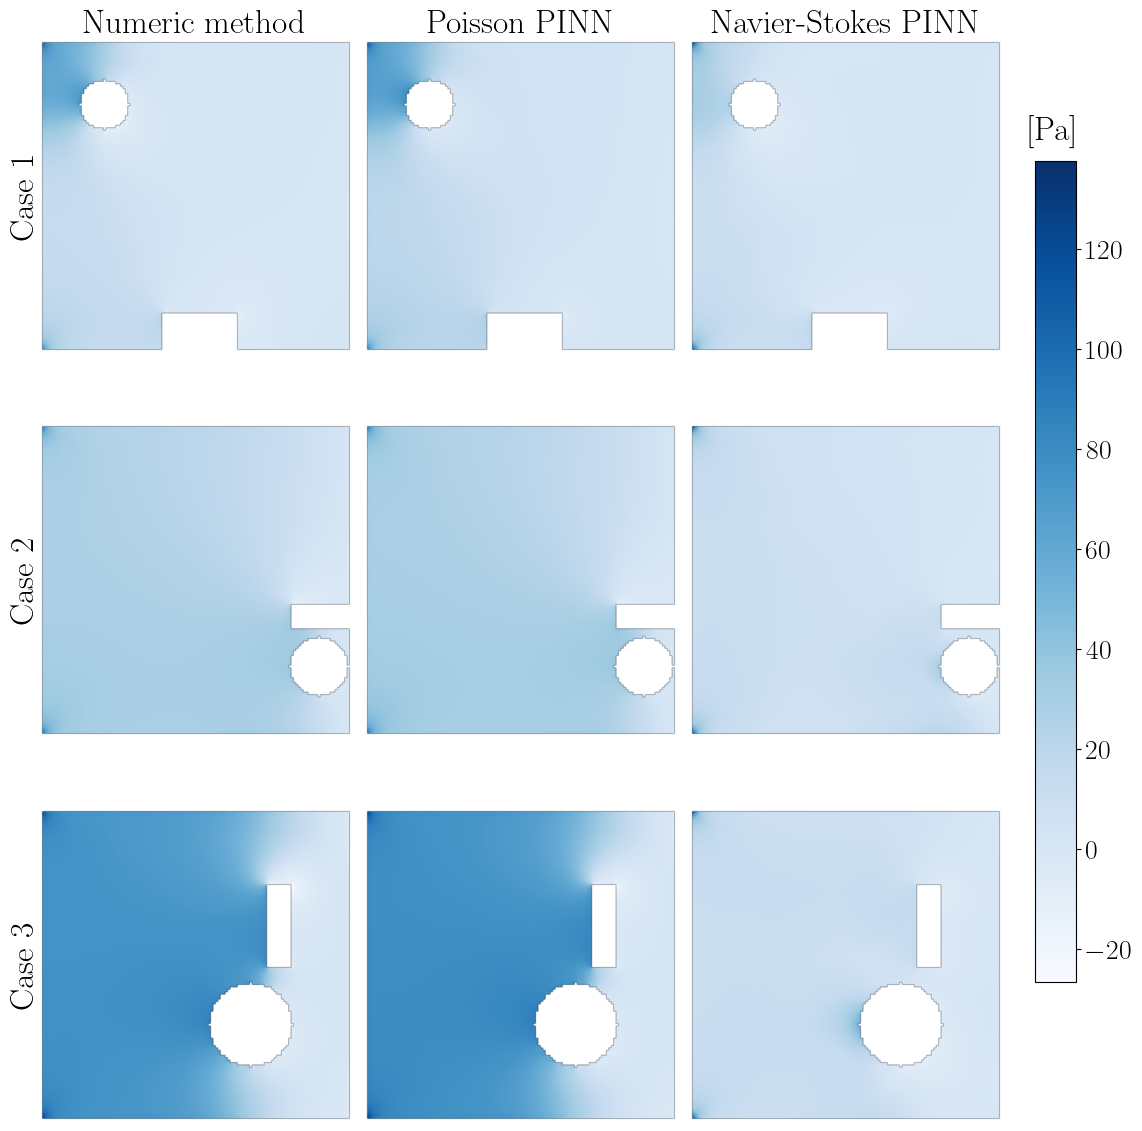

In [ ]:
n_cases = 3

cmap = "Blues"

vmin = []
vmax = []

for i in range(n_cases):
    Pn = np.array(results["p_numeric"][i], dtype=float)
    Pp = np.array(results["p_poisson"][i], dtype=float)
    Pf = np.array(results["p_full"][i], dtype=float)

    vmin.append(np.min([Pn.min(), Pp.min(), Pf.min()]))
    vmax.append(np.max([Pn.max(), Pp.max(), Pf.max()]))

vmin = np.min(vmin)
vmax = np.max(vmax)

fig, ax = plt.subplots(figsize=(12, 12), nrows=n_cases, ncols=3)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(n_cases):
    Pn = np.array(results["p_numeric"][i], dtype=float)
    Pp = np.array(results["p_poisson"][i], dtype=float)
    Pf = np.array(results["p_full"][i], dtype=float)

    boundary = np.array(results["boundaries"][i], dtype=float)

    height, width = np.shape(results["p_numeric"][i])[0], np.shape(results["p_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, 
                       np.linspace(0, height, height) + 0.5)
    

    ax[i, 0].imshow(Pn, vmin=vmin, vmax=vmax, cmap=cmap)
    ax[i, 1].imshow(Pp, vmin=vmin, vmax=vmax, cmap=cmap)
    im = ax[i, 2].imshow(Pf, vmin=vmin, vmax=vmax, cmap=cmap)

    for j in range(3):
        ax[i, j].imshow(boundary, cmap=bw_map)

    ax[i, 0].annotate(f"Case {i+1}", xy=(-0, 0.5), xycoords="axes fraction", rotation=90, va="center", ha="right", fontsize=24)

    for j in range(3):
        ax[i, j].axis("off")

cbar = fig.colorbar(im, ax=ax[:, 2])
cbar.ax.tick_params(labelsize=20)
cbar.ax.set_title(r"[Pa]", fontsize=24, pad=15)

ax[0, 0].set_title("Numeric method", fontsize=24)
ax[0, 1].set_title("Poisson PINN", fontsize=24)
ax[0, 2].set_title("Navier-Stokes PINN", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig("flow_examples_pressure.pdf")

### Pointwise errors

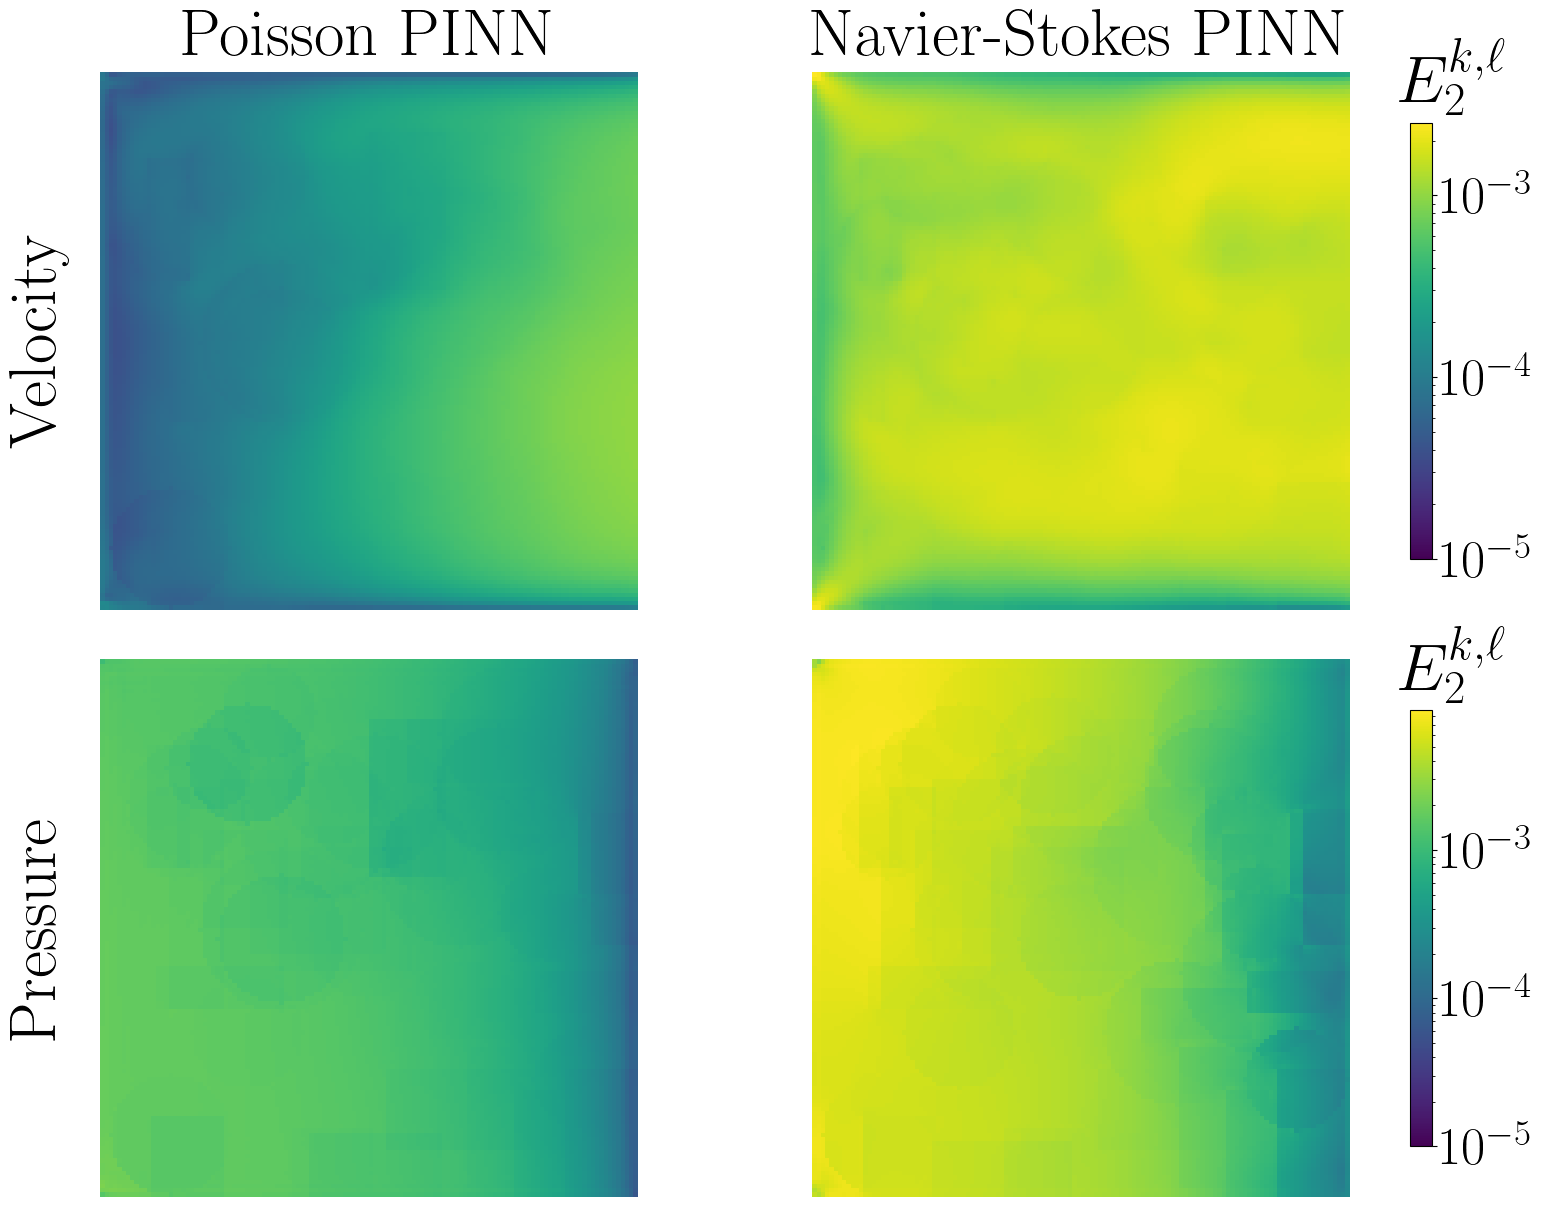

In [11]:
importlib.reload(analysis_functions)

errors = analysis_functions.compute_errors(results, norm="2")
analysis_functions.err_pointwise_plot(errors, title="mean_err_log.pdf")

### Single case errors

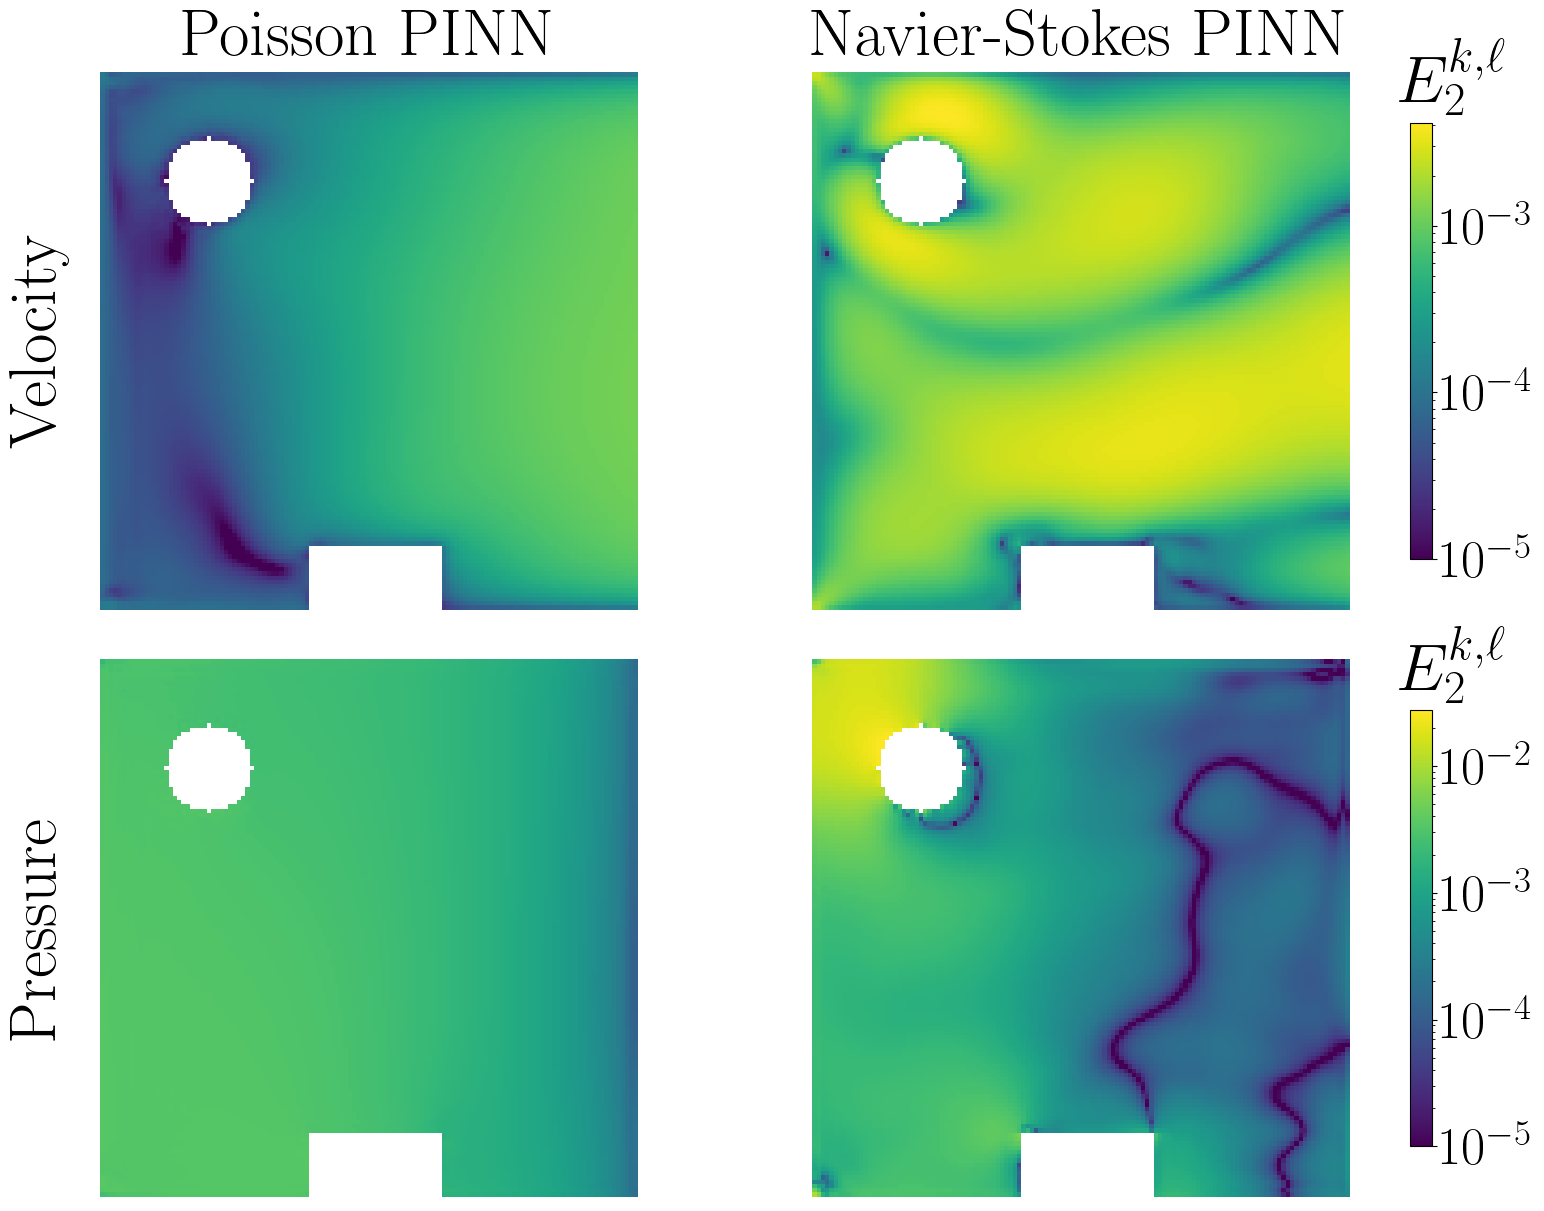

In [10]:
importlib.reload(analysis_functions)

case_num = 0

errors = analysis_functions.compute_errors(results, norm="2")
for k in errors.keys():
    errors[k] = [errors[k][case_num]]

analysis_functions.err_pointwise_plot(errors, title=f"err_case_{case_num}_log.pdf")

### Divergence errors

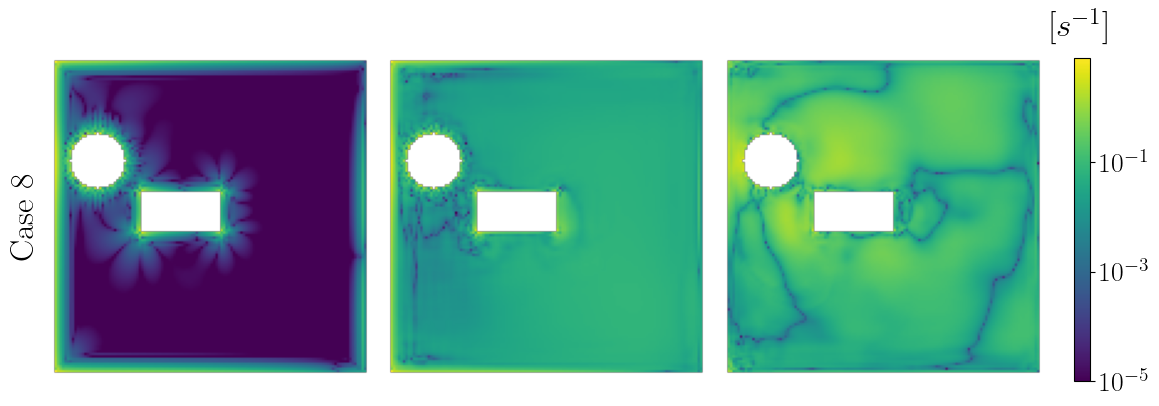

In [36]:
importlib.reload(analysis_functions)

case_num = 7

errors = analysis_functions.compute_errors(results, norm="1")
for k in errors.keys():
    errors[k] = [errors[k][case_num]]

analysis_functions.err_divergence_plot(errors, title=f"div_case_{case_num}.pdf", plot_title=f"Case {case_num + 1}", plot_titles=False)

### Momentum errors

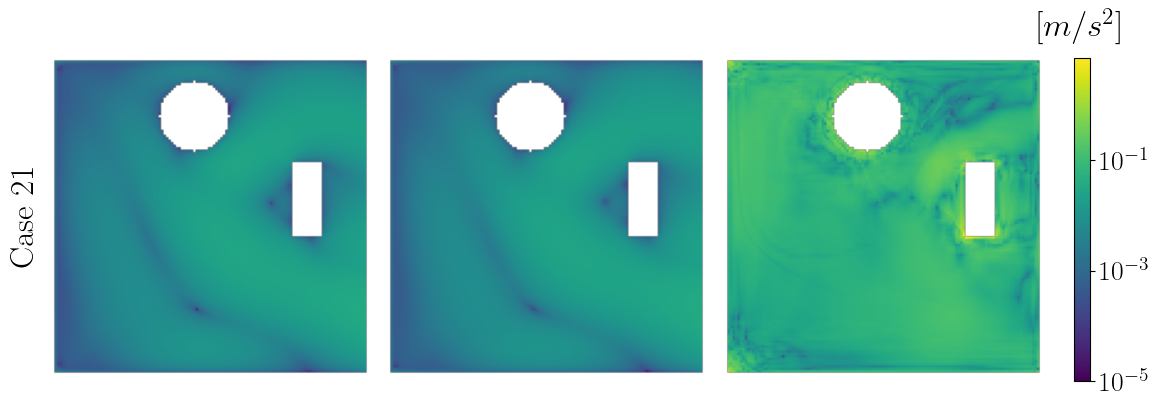

In [34]:
importlib.reload(analysis_functions)

case_num = 20

errors = analysis_functions.compute_errors(results, norm="1")
for k in errors.keys():
    errors[k] = [errors[k][case_num]]

analysis_functions.err_momentum_plot(errors, title=f"mom_case_{case_num}.pdf", plot_title=f"Case {case_num + 1}", plot_titles=False)

## Summary plots

### Histogram of errors

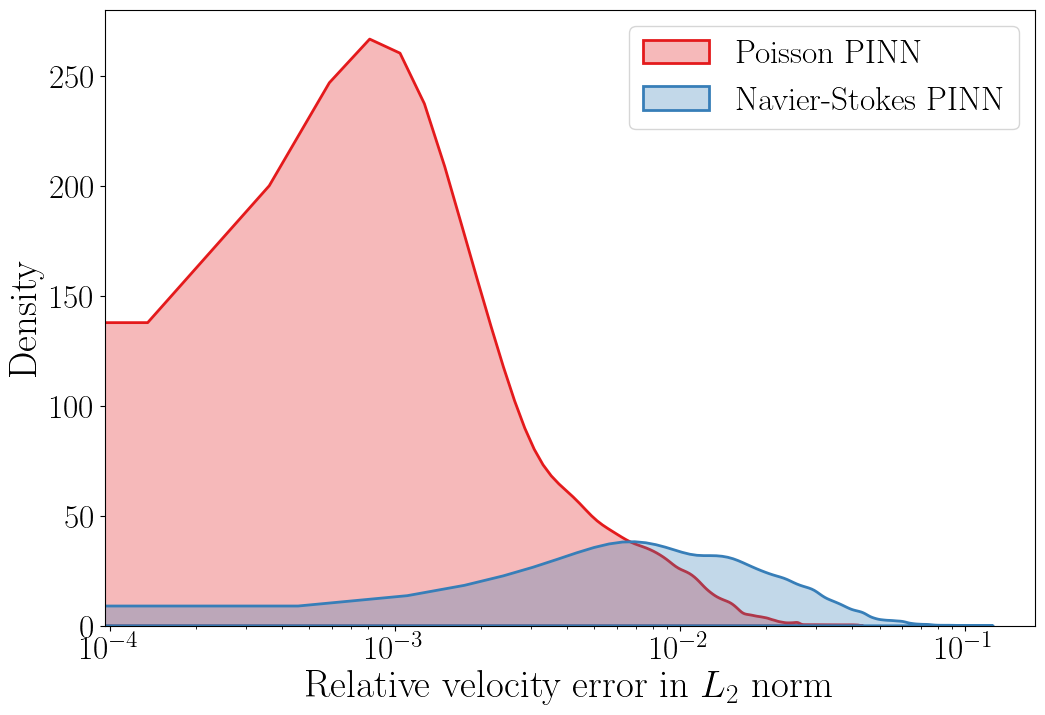

In [10]:
errors_poisson = np.array([])
errors_full = np.array([])

errors = compute_errors(results, norm="2")

for case_num in range(0, 25):
    bound = errors["boundaries"][case_num]

    errors_poisson = np.concatenate([errors_poisson, errors["u_err_poisson_pointwise"][case_num][bound != 1].flatten()])
    errors_full = np.concatenate([errors_full, errors["u_err_full_pointwise"][case_num][bound != 1].flatten()])

# errors = np.array(errors)
fig, ax = plt.subplots(figsize=(12, 8), nrows=1, ncols=1)

sns.kdeplot(errors_poisson, label="Poisson PINN", color="#e41a1c", fill=True, alpha=0.3, linewidth=2, ax=ax)
sns.kdeplot(errors_full, label="Navier-Stokes PINN", color="#377eb8", fill=True, alpha=0.3, linewidth=2, ax=ax)

ax.set_xlabel("Relative velocity error in $L_2$ norm", fontsize=28)
ax.set_ylabel("Density", fontsize=28)

ax.tick_params(axis='both', which='major', labelsize=24)

ax.set_xscale("log")

plt.legend(fontsize=24)

plt.savefig("kde_velocity.pdf")

plt.show()

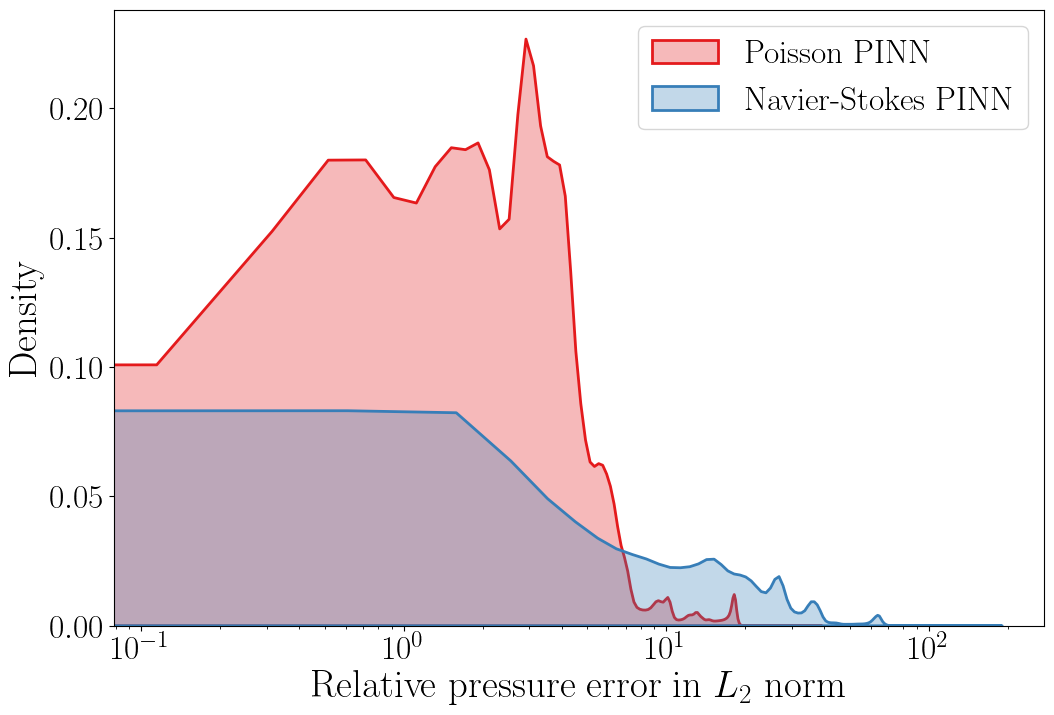

In [10]:
errors_poisson = np.array([])
errors_full = np.array([])

errors = compute_errors(results, norm="2")

for case_num in range(0, 25):
    bound = errors["boundaries"][case_num]

    errors_poisson = np.concatenate([errors_poisson, errors["p_err_poisson"][case_num][bound != 1].flatten()])
    errors_full = np.concatenate([errors_full, errors["p_err_full"][case_num][bound != 1].flatten()])

# errors = np.array(errors)
fig, ax = plt.subplots(figsize=(12, 8), nrows=1, ncols=1)

sns.kdeplot(errors_poisson, label="Poisson PINN", color="#e41a1c", fill=True, alpha=0.3, linewidth=2, ax=ax)
sns.kdeplot(errors_full, label="Navier-Stokes PINN", color="#377eb8", fill=True, alpha=0.3, linewidth=2, ax=ax)

ax.set_xlabel("Relative pressure error in $L_2$ norm", fontsize=28)
ax.set_ylabel("Density", fontsize=28)

ax.tick_params(axis='both', which='major', labelsize=24)

ax.set_xscale("log")

plt.legend(fontsize=24)

plt.savefig("kde_pressure.pdf")

plt.show()

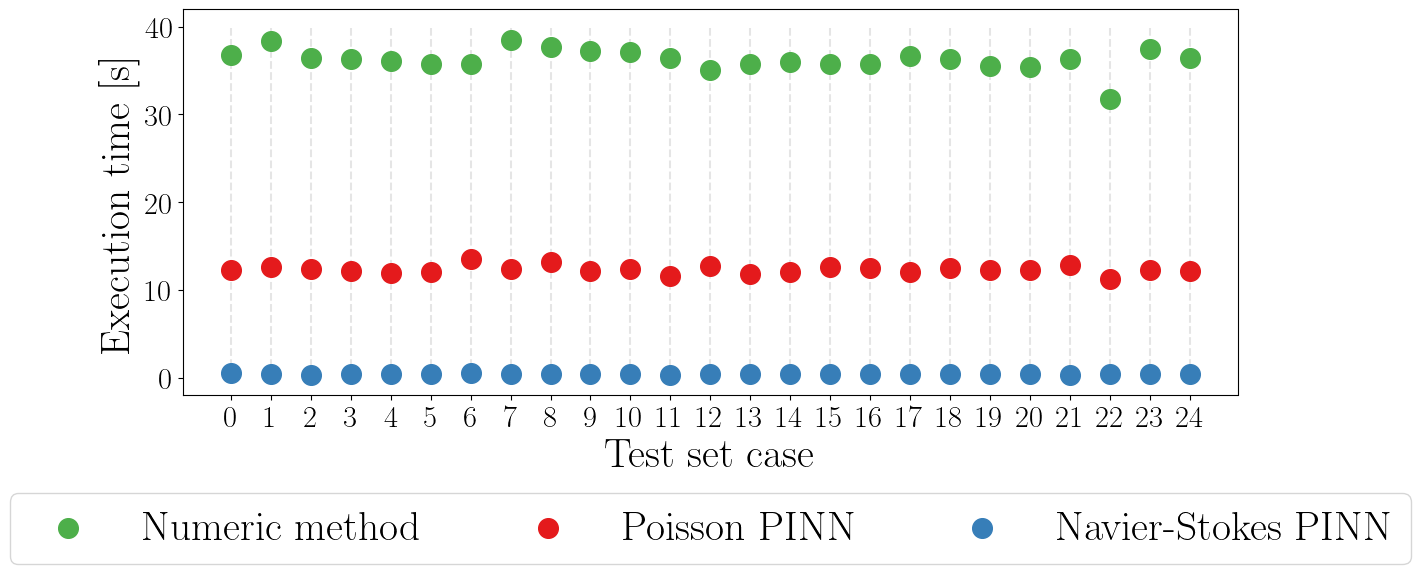

In [15]:
fig, ax = plt.subplots(figsize=(14, 6))

idx = np.arange(len(results["exec_times"]["numeric"]))

ax.vlines(idx, ymin=0, ymax=40, color="black", alpha=0.1, linestyles="--", zorder=0)

ax.scatter(idx, results["exec_times"]["numeric"], color="#4daf4a", label="Numeric method", s=200)
ax.scatter(idx, results["exec_times"]["poisson"], color="#e41a1c", label="Poisson PINN", s=200)
ax.scatter(idx, results["exec_times"]["full"], color="#377eb8", label="Navier-Stokes PINN", s=200)

width = 0.3

ax.set_xticks(idx)
ax.set_xticklabels(idx)
ax.tick_params(axis='both', which='major', labelsize=22)

ax.set_xlabel("Test set case", fontsize=30)
ax.set_ylabel("Execution time [s]", fontsize=30)

# ax.legend(fontsize=24, loc='upper left', bbox_to_anchor=(1, 1), frameon=True)
ax.legend(fontsize=30, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=True)

plt.tight_layout()

plt.savefig("exec_times.pdf")

In [92]:
print("Execution times")
print(f"numeric = {results["exec_times"]["numeric"].mean()} +- {results["exec_times"]["numeric"].std()}")
print(f"poisson = {results["exec_times"]["poisson"].mean()} +- {results["exec_times"]["poisson"].std()}")
print(f"full = {results["exec_times"]["full"].mean()} +- {results["exec_times"]["full"].std()}")

Execution times
numeric = 36.26456961631775 +- 1.281128798792494
poisson = 12.326171684265137 +- 0.4623323086222934
full = 0.428245849609375 +- 0.03980697251253322


Poisson: 2.944400207489938 +- 0.11198821809476038
NS: 85.3674826643095 +- 8.155519100728528


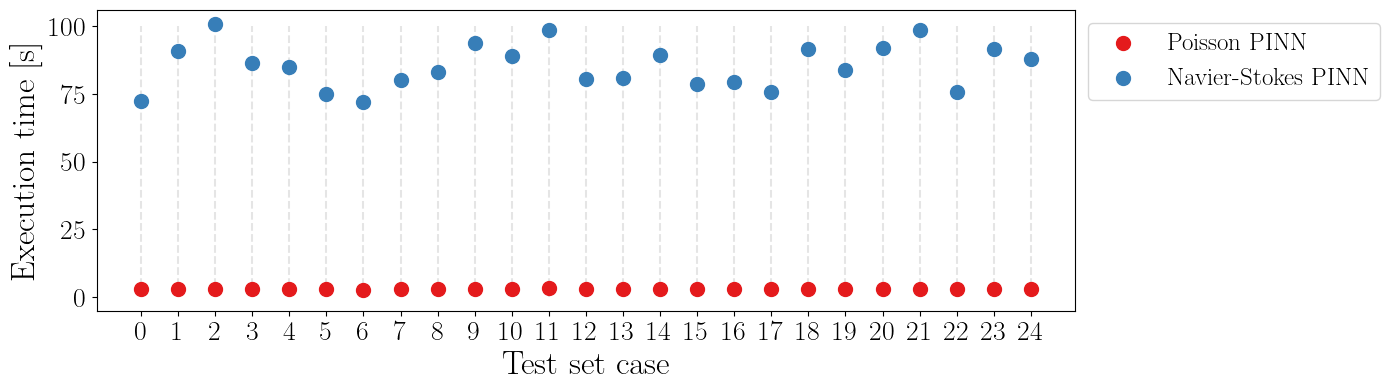

In [32]:
def relative_improvement(t_baseline, t):
    # return (t_baseline - t) / t_baseline
    return t_baseline / t

ri_poisson = relative_improvement(results["exec_times"]["numeric"], results["exec_times"]["poisson"])
ri_ns = relative_improvement(results["exec_times"]["numeric"], results["exec_times"]["full"])

print(f"Poisson: {np.mean(ri_poisson)} +- {np.std(ri_poisson)}")
print(f"NS: {np.mean(ri_ns)} +- {np.std(ri_ns)}")

fig, ax = plt.subplots(figsize=(14, 4))

idx = np.arange(len(results["exec_times"]["numeric"]))

ax.vlines(idx, ymin=0, ymax=100, color="black", alpha=0.1, linestyles="--", zorder=0)

# ax.scatter(idx, results["exec_times"]["numeric"], color="#4daf4a", label="Numeric method", s=100)
ax.scatter(idx, ri_poisson, color="#e41a1c", label="Poisson PINN", s=100)
ax.scatter(idx, ri_ns, color="#377eb8", label="Navier-Stokes PINN", s=100)

width = 0.3

ax.set_xticks(idx)
ax.set_xticklabels(idx)
ax.tick_params(axis='both', which='major', labelsize=20)

ax.set_xlabel("Test set case", fontsize=24)
ax.set_ylabel("Execution time [s]", fontsize=24)

ax.legend(fontsize=18, loc='upper left', bbox_to_anchor=(1, 1), frameon=True)

plt.tight_layout()

# plt.savefig("exec_times.pdf")